In [1]:
# For tips on running notebooks in Google Colab, see
# https://docs.pytorch.org/tutorials/beginner/colab
%matplotlib inline

TorchVision 物件偵測 (Object Detection) 微調 (Finetuning) 教學
================================================
這份筆記本將帶你一步一步了解如何使用 PyTorch 和 TorchVision 來訓練一個能同時做到「物件偵測」(找出物件的邊界框) 和「實例分割」(Instance Segmentation, 描繪出物件的精確像素輪廓) 的模型。

在這篇教學中，我們將微調 (finetuning) 一個預先訓練好的 [Mask R-CNN](https://arxiv.org/abs/1703.06870) 模型。我們使用的資料集是 [Penn-Fudan 行人偵測與分割資料集](https://www.cis.upenn.edu/~jshi/ped_html/)。該資料集包含 170 張圖片和 345 個行人的實例。

### 💡 給初學者的觀念：為什麼要微調 (Finetuning)？
作為初學者，從頭開始訓練一個強大的模型需要極大量的資料、算力與時間。微調的意思是我們拿一個已經在超大型資料集上學會如何「看」圖片的模型，然後稍微訓練它，讓它適應我們特定的任務（在這裡是抓出行人）。這樣既省時，效果又好！

定義資料集 (Defining the Dataset)
====================

要讓模型順利讀取我們的資料，我們必須按照 PyTorch 的規定來撰寫一個資料集類別。

### 💡 為什麼要這樣寫？
在 PyTorch 裡，資料載入器 (DataLoader) 需要知道你的資料集有多大、以及如何精準抓取「特定一筆資料」。因此你的自定義類別必須繼承標準的 `torch.utils.data.Dataset`，並且實作兩個關鍵的函式：
1. `__len__`：回傳資料集的總數量。
2. `__getitem__`：當 PyTorch 說「給我第 `idx` 筆資料」時，這個函式要負責讀取圖片與標籤並回傳。

針對物件偵測，`__getitem__` 必須回傳一個 Tuple (元組)：
- `image`：圖片，格式為 `[3, H, W]` 的 Tensor (張量)。
- `target`：這是一個字典 (dict)，包含以下資訊：
    - `boxes`：邊界框 (Bounding boxes)，代表每個物件在圖片中的長方形座標 `[x0, y0, x1, y1]`。
    - `labels`：每個物件的類別標籤 (以整數表示)。請注意，`0` 永遠保留給背景 (background)。假設只有貓和狗，你應該用 `1` 代表貓，`2` 代表狗。
    - `image_id`：圖片的唯一編號。
    - `area`：邊界框的面積 (用來評估不同大小物件的準確度)。
    - `iscrowd`：用來標記是否為擁擠的人群 (如果是 True，評估時會忽略)。
    - `masks`：(選用) 實例分割的遮罩，標示出物件的精確像素位置。

如果你按照上述格式準備資料，就能直接套用官方提供的訓練與評估程式碼！

### 撰寫 PennFudan 的自定義資料集

在開始寫 Python 類別之前，我們需要先下載資料。下方的程式碼會自動幫你下載資料集並解壓縮 (使用 `wget` 和 `unzip` 指令)，然後用 `matplotlib` 畫出其中一張圖片與它的遮罩 (Mask) 讓你看看長什麼樣子。

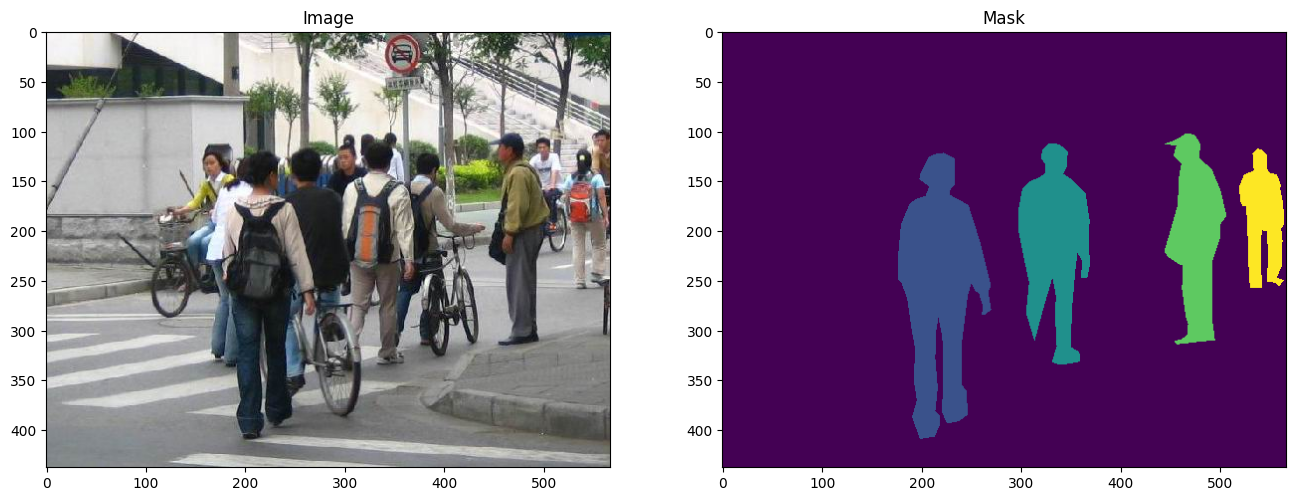

In [3]:
# Download and extract the dataset first if it doesn't exist
import os
if not os.path.exists("data/PennFudanPed"):
    os.makedirs("data", exist_ok=True)
    os.system("wget https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip -P data")
    os.system("cd data && unzip -q PennFudanPed.zip")

import matplotlib.pyplot as plt
from torchvision.io import read_image

image = read_image("data/PennFudanPed/PNGImages/FudanPed00046.png")
mask = read_image("data/PennFudanPed/PedMasks/FudanPed00046_mask.png")

plt.figure(figsize=(16, 8))
plt.subplot(121)
plt.title("Image")
plt.imshow(image.permute(1, 2, 0))
plt.subplot(122)
plt.title("Mask")
plt.imshow(mask.permute(1, 2, 0))

太棒了！正如上方顯示的，每張圖片都有對應的分割遮罩 (Segmentation mask)，遮罩上的每種不同顏色代表一個不同的行人實例 (Instance)。

接下來，我們要正式把 `torch.utils.data.Dataset` 寫出來。在下方的程式碼中，我們會把圖片、邊界框與遮罩轉換成特殊的 `torchvision.tv_tensors` 格式。

### 💡 程式碼在做什麼？為什麼要這樣寫？
下面的程式碼定義了 `PennFudanDataset` 類別：
1. **`__init__`**：初始化時，我們把圖片和遮罩的檔案名稱都讀進來。**為什麼要用 `sorted()`？** 確保圖片清單和遮罩清單的順序完全一致，這樣第 $i$ 張圖片才會對應到第 $i$ 個遮罩。
2. **`__getitem__`**：
    - 讀取圖片與對應的遮罩。
    - **`obj_ids = torch.unique(mask)`**：因為不同的人是用不同的像素顏色值 (ID) 儲存的，這行找出這張圖裡有幾個人。並移除 ID 0 (背景)。
    - **`masks = (mask == obj_ids[:, None, None])`**：這裡運用了強大的廣播 (broadcasting) 機制。它將原本一張含有多種顏色的遮罩，拆解成「好幾張只有 0 和 1 的二值遮罩 (binary masks)」，每一張代表一個獨立的行人。
    - **`boxes = masks_to_boxes(masks)`**：這是一個極度方便的工具函數！它會自動掃描上述的遮罩，找出每個行人的最左、最右、最上、最下邊界，直接幫我們算出邊界框座標，省去我們自己寫迴圈計算的麻煩。
    - 最後，將所有的變數塞進 `target` 字典中，並將它們包裝成 `tv_tensors.Image` 或 `tv_tensors.BoundingBoxes`。**為什麼要包裝？** 因為這樣稍後在做「資料增強」(Data Augmentation，例如把圖片翻轉) 時，TorchVision 會自動連同標籤、遮罩跟邊界框一起跟著翻轉，避免圖片翻了但框沒翻的慘劇發生！

In [4]:
import os
import torch

from torchvision.io import read_image
from torchvision.ops.boxes import masks_to_boxes
from torchvision import tv_tensors
from torchvision.transforms.v2 import functional as F


class PennFudanDataset(torch.utils.data.Dataset):
    def __init__(self, root, transforms):
        self.root = root
        self.transforms = transforms
        # load all image files, sorting them to
        # ensure that they are aligned
        self.imgs = list(sorted(os.listdir(os.path.join(root, "PNGImages"))))
        self.masks = list(sorted(os.listdir(os.path.join(root, "PedMasks"))))

    def __getitem__(self, idx):
        # load images and masks
        img_path = os.path.join(self.root, "PNGImages", self.imgs[idx])
        mask_path = os.path.join(self.root, "PedMasks", self.masks[idx])
        img = read_image(img_path)
        mask = read_image(mask_path)
        # instances are encoded as different colors
        obj_ids = torch.unique(mask)
        # first id is the background, so remove it
        obj_ids = obj_ids[1:]
        num_objs = len(obj_ids)

        # split the color-encoded mask into a set
        # of binary masks
        masks = (mask == obj_ids[:, None, None]).to(dtype=torch.uint8)

        # get bounding box coordinates for each mask
        boxes = masks_to_boxes(masks)

        # there is only one class
        labels = torch.ones((num_objs,), dtype=torch.int64)

        image_id = idx
        area = (boxes[:, 3] - boxes[:, 1]) * (boxes[:, 2] - boxes[:, 0])
        # suppose all instances are not crowd
        iscrowd = torch.zeros((num_objs,), dtype=torch.int64)

        # Wrap sample and targets into torchvision tv_tensors:
        img = tv_tensors.Image(img)

        target = {}
        target["boxes"] = tv_tensors.BoundingBoxes(boxes, format="XYXY", canvas_size=F.get_size(img))
        target["masks"] = tv_tensors.Mask(masks)
        target["labels"] = labels
        target["image_id"] = image_id
        target["area"] = area
        target["iscrowd"] = iscrowd

        if self.transforms is not None:
            img, target = self.transforms(img, target)

        return img, target

    def __len__(self):
        return len(self.imgs)

That's all for the dataset. Now let's define a model that can perform
predictions on this dataset.

Defining your model
===================

In this tutorial, we will be using [Mask
R-CNN](https://arxiv.org/abs/1703.06870), which is based on top of
[Faster R-CNN](https://arxiv.org/abs/1506.01497). Faster R-CNN is a
model that predicts both bounding boxes and class scores for potential
objects in the image.

![image](https://pytorch.org/tutorials/_static/img/tv_tutorial/tv_image03.png)

Mask R-CNN adds an extra branch into Faster R-CNN, which also predicts
segmentation masks for each instance.

![image](https://pytorch.org/tutorials/_static/img/tv_tutorial/tv_image04.png)

There are two common situations where one might want to modify one of
the available models in TorchVision Model Zoo. The first is when we want
to start from a pre-trained model, and just finetune the last layer. The
other is when we want to replace the backbone of the model with a
different one (for faster predictions, for example).

Let's go see how we would do one or another in the following sections.

1 - Finetuning from a pretrained model
--------------------------------------

Let's suppose that you want to start from a model pre-trained on COCO
and want to finetune it for your particular classes. Here is a possible
way of doing it:


In [5]:
import torchvision
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

# load a model pre-trained on COCO
model = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights="DEFAULT")

# replace the classifier with a new one, that has
# num_classes which is user-defined
num_classes = 2  # 1 class (person) + background
# get number of input features for the classifier
in_features = model.roi_heads.box_predictor.cls_score.in_features
# replace the pre-trained head with a new one
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:01<00:00, 108MB/s]


2 - Modifying the model to add a different backbone
===================================================


In [6]:
import torchvision
from torchvision.models.detection import FasterRCNN
from torchvision.models.detection.rpn import AnchorGenerator

# load a pre-trained model for classification and return
# only the features
backbone = torchvision.models.mobilenet_v2(weights="DEFAULT").features
# ``FasterRCNN`` needs to know the number of
# output channels in a backbone. For mobilenet_v2, it's 1280
# so we need to add it here
backbone.out_channels = 1280

# let's make the RPN generate 5 x 3 anchors per spatial
# location, with 5 different sizes and 3 different aspect
# ratios. We have a Tuple[Tuple[int]] because each feature
# map could potentially have different sizes and
# aspect ratios
anchor_generator = AnchorGenerator(
    sizes=((32, 64, 128, 256, 512),),
    aspect_ratios=((0.5, 1.0, 2.0),)
)

# let's define what are the feature maps that we will
# use to perform the region of interest cropping, as well as
# the size of the crop after rescaling.
# if your backbone returns a Tensor, featmap_names is expected to
# be [0]. More generally, the backbone should return an
# ``OrderedDict[Tensor]``, and in ``featmap_names`` you can choose which
# feature maps to use.
roi_pooler = torchvision.ops.MultiScaleRoIAlign(
    featmap_names=['0'],
    output_size=7,
    sampling_ratio=2
)

# put the pieces together inside a Faster-RCNN model
model = FasterRCNN(
    backbone,
    num_classes=2,
    rpn_anchor_generator=anchor_generator,
    box_roi_pool=roi_pooler
)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 96.6MB/s]


Object detection and instance segmentation model for PennFudan Dataset
======================================================================

In our case, we want to finetune from a pre-trained model, given that
our dataset is very small, so we will be following approach number 1.

Here we want to also compute the instance segmentation masks, so we will
be using Mask R-CNN:


In [7]:
import torchvision
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor


def get_model_instance_segmentation(num_classes):
    # load an instance segmentation model pre-trained on COCO
    model = torchvision.models.detection.maskrcnn_resnet50_fpn(weights="DEFAULT")

    # get number of input features for the classifier
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    # replace the pre-trained head with a new one
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

    # now get the number of input features for the mask classifier
    in_features_mask = model.roi_heads.mask_predictor.conv5_mask.in_channels
    hidden_layer = 256
    # and replace the mask predictor with a new one
    model.roi_heads.mask_predictor = MaskRCNNPredictor(
        in_features_mask,
        hidden_layer,
        num_classes
    )

    return model

That's it, this will make `model` be ready to be trained and evaluated
on your custom dataset.

Putting everything together
===========================

In `references/detection/`, we have a number of helper functions to
simplify training and evaluating detection models. Here, we will use
`references/detection/engine.py` and `references/detection/utils.py`.
Just download everything under `references/detection` to your folder and
use them here. On Linux if you have `wget`, you can download them using
below commands:


In [8]:
os.system("wget https://raw.githubusercontent.com/pytorch/vision/main/references/detection/engine.py")
os.system("wget https://raw.githubusercontent.com/pytorch/vision/main/references/detection/utils.py")
os.system("wget https://raw.githubusercontent.com/pytorch/vision/main/references/detection/coco_utils.py")
os.system("wget https://raw.githubusercontent.com/pytorch/vision/main/references/detection/coco_eval.py")
os.system("wget https://raw.githubusercontent.com/pytorch/vision/main/references/detection/transforms.py")

0

Since v0.15.0 torchvision provides [new Transforms
API](https://pytorch.org/vision/stable/transforms.html) to easily write
data augmentation pipelines for Object Detection and Segmentation tasks.

Let's write some helper functions for data augmentation /
transformation:


In [9]:
from torchvision.transforms import v2 as T


def get_transform(train):
    transforms = []
    if train:
        transforms.append(T.RandomHorizontalFlip(0.5))
    transforms.append(T.ToDtype(torch.float, scale=True))
    transforms.append(T.ToPureTensor())
    return T.Compose(transforms)

Testing `forward()` method (Optional)
=====================================

Before iterating over the dataset, it\'s good to see what the model
expects during training and inference time on sample data.


In [10]:
import utils

model = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights="DEFAULT")
dataset = PennFudanDataset('data/PennFudanPed', get_transform(train=True))
data_loader = torch.utils.data.DataLoader(
    dataset,
    batch_size=2,
    shuffle=True,
    collate_fn=utils.collate_fn
)

# For Training
images, targets = next(iter(data_loader))
images = list(image for image in images)
targets = [{k: v for k, v in t.items()} for t in targets]
output = model(images, targets)  # Returns losses and detections
print(output)

# For inference
model.eval()
x = [torch.rand(3, 300, 400), torch.rand(3, 500, 400)]
predictions = model(x)  # Returns predictions
print(predictions[0])

{'loss_classifier': tensor(0.0928, grad_fn=<NllLossBackward0>), 'loss_box_reg': tensor(0.0282, grad_fn=<DivBackward0>), 'loss_objectness': tensor(0.0104, grad_fn=<BinaryCrossEntropyWithLogitsBackward0>), 'loss_rpn_box_reg': tensor(0.0011, grad_fn=<DivBackward0>)}
{'boxes': tensor([], size=(0, 4), grad_fn=<StackBackward0>), 'labels': tensor([], dtype=torch.int64), 'scores': tensor([], grad_fn=<IndexBackward0>)}


We want to be able to train our model on an
[accelerator](https://pytorch.org/docs/stable/torch.html#accelerators)
such as CUDA, MPS, MTIA, or XPU. Let's now write the main function which
performs the training and the validation:


In [11]:
from engine import train_one_epoch, evaluate

# train on the accelerator or on the CPU, if an accelerator is not available
device = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else torch.device('cpu')

# our dataset has two classes only - background and person
num_classes = 2
# use our dataset and defined transformations
dataset = PennFudanDataset('data/PennFudanPed', get_transform(train=True))
dataset_test = PennFudanDataset('data/PennFudanPed', get_transform(train=False))

# split the dataset in train and test set
indices = torch.randperm(len(dataset)).tolist()
dataset = torch.utils.data.Subset(dataset, indices[:-50])
dataset_test = torch.utils.data.Subset(dataset_test, indices[-50:])

# define training and validation data loaders
data_loader = torch.utils.data.DataLoader(
    dataset,
    batch_size=2,
    shuffle=True,
    collate_fn=utils.collate_fn
)

data_loader_test = torch.utils.data.DataLoader(
    dataset_test,
    batch_size=1,
    shuffle=False,
    collate_fn=utils.collate_fn
)

# get the model using our helper function
model = get_model_instance_segmentation(num_classes)

# move model to the right device
model.to(device)

# construct an optimizer
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(
    params,
    lr=0.005,
    momentum=0.9,
    weight_decay=0.0005
)

# and a learning rate scheduler
lr_scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=3,
    gamma=0.1
)

# let's train it just for 2 epochs
num_epochs = 2

for epoch in range(num_epochs):
    # train for one epoch, printing every 10 iterations
    train_one_epoch(model, optimizer, data_loader, device, epoch, print_freq=10)
    # update the learning rate
    lr_scheduler.step()
    # evaluate on the test dataset
    evaluate(model, data_loader_test, device=device)

print("That's it!")

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:01<00:00, 160MB/s]
/content/engine.py:30: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=scaler is not None):


Epoch: [0]  [ 0/60]  eta: 0:39:25  lr: 0.000090  loss: 9.8699 (9.8699)  loss_classifier: 0.7182 (0.7182)  loss_box_reg: 0.2301 (0.2301)  loss_mask: 8.8418 (8.8418)  loss_objectness: 0.0750 (0.0750)  loss_rpn_box_reg: 0.0048 (0.0048)  time: 39.4236  data: 0.0298
Epoch: [0]  [10/60]  eta: 0:39:19  lr: 0.000936  loss: 2.4158 (4.0722)  loss_classifier: 0.4420 (0.4736)  loss_box_reg: 0.2770 (0.2972)  loss_mask: 1.6408 (3.2623)  loss_objectness: 0.0267 (0.0332)  loss_rpn_box_reg: 0.0048 (0.0060)  time: 47.1876  data: 0.0339
Epoch: [0]  [20/60]  eta: 0:31:33  lr: 0.001783  loss: 1.0196 (2.4793)  loss_classifier: 0.1969 (0.3119)  loss_box_reg: 0.2414 (0.2593)  loss_mask: 0.4225 (1.8782)  loss_objectness: 0.0156 (0.0235)  loss_rpn_box_reg: 0.0039 (0.0064)  time: 47.7406  data: 0.0353
Epoch: [0]  [30/60]  eta: 0:24:16  lr: 0.002629  loss: 0.6567 (1.8890)  loss_classifier: 0.1073 (0.2513)  loss_box_reg: 0.2219 (0.2563)  loss_mask: 0.2998 (1.3553)  loss_objectness: 0.0087 (0.0191)  loss_rpn_box_re

So after one epoch of training, we obtain a COCO-style mAP \> 50, and a
mask mAP of 65.

But what do the predictions look like? Let's take one image in the
dataset and verify


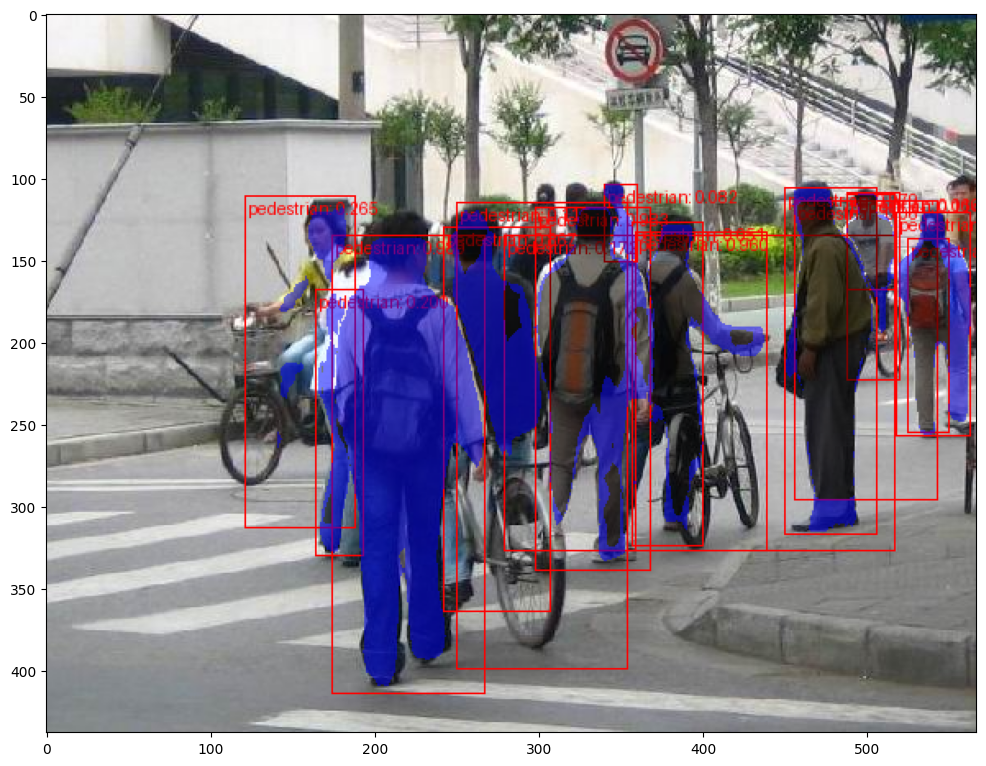

In [12]:
import matplotlib.pyplot as plt

from torchvision.utils import draw_bounding_boxes, draw_segmentation_masks


image = read_image("data/PennFudanPed/PNGImages/FudanPed00046.png")
eval_transform = get_transform(train=False)

model.eval()
with torch.no_grad():
    x = eval_transform(image)
    # convert RGBA -> RGB and move to device
    x = x[:3, ...].to(device)
    predictions = model([x, ])
    pred = predictions[0]


image = (255.0 * (image - image.min()) / (image.max() - image.min())).to(torch.uint8)
image = image[:3, ...]
pred_labels = [f"pedestrian: {score:.3f}" for label, score in zip(pred["labels"], pred["scores"])]
pred_boxes = pred["boxes"].long()
output_image = draw_bounding_boxes(image, pred_boxes, pred_labels, colors="red")

masks = (pred["masks"] > 0.7).squeeze(1)
output_image = draw_segmentation_masks(output_image, masks, alpha=0.5, colors="blue")


plt.figure(figsize=(12, 12))
plt.imshow(output_image.permute(1, 2, 0))

The results look good!

Wrapping up
===========

In this tutorial, you have learned how to create your own training
pipeline for object detection models on a custom dataset. For that, you
wrote a `torch.utils.data.Dataset`{.interpreted-text role="class"} class
that returns the images and the ground truth boxes and segmentation
masks. You also leveraged a Mask R-CNN model pre-trained on COCO
train2017 in order to perform transfer learning on this new dataset.

For a more complete example, which includes multi-machine / multi-GPU
training, check `references/detection/train.py`, which is present in the
torchvision repository.
